## 01. Project Setup

Jalankan cell setup dari root proyek atau folder `notebooks`. Tidak ada training otomatis.


In [1]:
from pathlib import Path
import sys
import warnings
import json
import os
import gc
import csv
from collections import Counter

def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "data/metadata/split_manifest.csv").is_file() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Root proyek tidak ditemukan; jalankan dari root atau notebooks.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from src.models.efficientnet_b2 import *
from src.data.dataloader import load_manifest_records, create_dataloader
from src.data.preprocessing import coerce_rgb_image, load_active_class_mapping
from src.callbacks import TrainingManager, EarlyStopping
from src.callbacks.lr_scheduler import build_scheduler
from src.callbacks.model_checkpoint import load_checkpoint
from src.training.resume import resume_from_checkpoint
from src.training.validate import validate_one_epoch
from src.evaluation.training_monitoring import load_training_history, history_review
from src.evaluation.visualization import plot_learning_curves
from src.inference.competition import audit_competition_test, competition_paths, load_submission_template
from src.inference.competition import CompetitionTestDataset, create_competition_dataloader
from src.inference.predict import predict_torch_classifier
from src.inference.submission import write_submission_csv, validate_submission_csv
print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification


## 02. Experiment Configuration

Semua flag eksekusi default `False`. Aktifkan hanya fase yang diinginkan, lalu jalankan ulang cell tersebut. Resume harus eksplisit; pilih batch 4 atau 2 jika VRAM tidak cukup.


In [19]:
RUN_HEAD_TRAINING = False
RUN_FINE_TUNING = False
RUN_VALIDATION_EVALUATION = True
RUN_TEST_INFERENCE = False
RESUME_HEAD = False
RESUME_FINE_TUNING = False
BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 1
NUM_WORKERS = 0
SEED = 42
CONFIG = load_experiment_config(PROJECT_ROOT)
set_global_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE), "| VRAM GiB:", round(torch.cuda.get_device_properties(DEVICE).total_memory / 1024**3, 2))
else:
    warnings.warn("CUDA tidak tersedia: fallback CPU, training akan jauh lebih lambat.")
print("Device:", DEVICE, "| AMP:", DEVICE.type == "cuda", "| Config:", CONFIG)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU | VRAM GiB: 4.0
Device: cuda | AMP: True | Config: {'model_type': 'efficientnet_b2', 'framework': 'torchvision', 'pretrained': True, 'weights': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'preprocessing': {'profile': 'torchvision_imagenet_fallback', 'metadata_priority': 'official', 'overrides': {'image_size': [288, 288], 'resize_size': 288, 'interpolation': 'bicubic'}}, 'augmentation': {'enabled': True, 'profile': 'pretrained_light'}}


## 03. Dataset Audit

Hanya manifest V1 aktif. Verifikasi path, isi train/validation dan hitung internal test tanpa melakukan evaluasi.


In [3]:
manifest = pd.read_csv(PROJECT_ROOT / "data/metadata/split_manifest.csv", dtype=str)
split_counts = manifest.groupby("split").size().to_dict()
assert split_counts == {"train": 1340, "val": 383, "test_internal": 191}, split_counts
assert manifest["source_relative_path"].str.replace("\\", "/", regex=False).str.startswith("data/extracted/v1/train/").all()
assert not manifest["source_relative_path"].str.contains("/v5/", case=False, regex=False).any()
train_records = load_manifest_records("train", PROJECT_ROOT)
val_records = load_manifest_records("val", PROJECT_ROOT)
internal_records = load_manifest_records("test_internal", PROJECT_ROOT)
assert len(internal_records) == 191
for record in (*train_records, *val_records):
    with Image.open(PROJECT_ROOT / record.processed_relative_path) as image:
        image.verify()
CLASS_MAPPING = load_active_class_mapping(PROJECT_ROOT)
EXPECTED_CLASSES = {"cardboard", "electronic", "foodwaste", "glass", "metal", "paper", "plastic", "textile"}
assert set(CLASS_MAPPING) == EXPECTED_CLASSES and set(CLASS_MAPPING.values()) == set(range(8))
print("Split:", split_counts, "| Train/validation dapat dibaca:", len(train_records) + len(val_records))
print("Mapping aktif:", CLASS_MAPPING)

Split: {'test_internal': 191, 'train': 1340, 'val': 383} | Train/validation dapat dibaca: 1723
Mapping aktif: {'cardboard': 0, 'electronic': 1, 'foodwaste': 2, 'glass': 3, 'metal': 4, 'paper': 5, 'plastic': 6, 'textile': 7}


## 04. Class Distribution

Distribusi berasal dari manifest; split internal test hanya dihitung sebagai audit, tidak dipakai memilih model.


In [4]:
distribution = pd.crosstab(manifest["class_name"], manifest["split"])
display(distribution)

split,test_internal,train,val
class_name,,,
cardboard,26,183,52
electronic,20,143,41
foodwaste,24,172,49
glass,21,145,41
metal,24,167,48
paper,22,156,45
plastic,32,222,64
textile,22,152,43


## 05. EfficientNet-B2 Preprocessing

Validation dan inference memakai transform resmi bobot ImageNet: RGB, resize dan center crop 288, bicubic, float32 dan normalisasi ImageNet satu kali.


In [5]:
TRAIN_TRANSFORM, VALIDATION_TRANSFORM, PREPROCESSING = build_efficientnet_b2_transforms()
print(PREPROCESSING)
print("Official transform:", VALIDATION_TRANSFORM)
print("Validasi synthetic:", validate_preprocessing(VALIDATION_TRANSFORM))

{'source': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'color_mode': 'RGB', 'resize': 288, 'center_crop': 288, 'interpolation': 'bicubic', 'pixel_scaling': '[0, 1] before normalization', 'normalization': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'training_augmentation': {'horizontal_flip': True, 'rotation_degrees': 15, 'shear_degrees': 10, 'brightness': 0.1}}
Official transform: ImageClassification(
    crop_size=[288]
    resize_size=[288]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)
Validasi synthetic: {'shape': (3, 288, 288), 'dtype': 'torch.float32', 'finite': True}


## 06. Training Augmentation Preview

Preview memakai satu gambar train; flip, rotasi <=15 derajat, shear <=10 derajat dan brightness <=10%. Tinjau apakah crop atau affine menghilangkan ciri kelas.


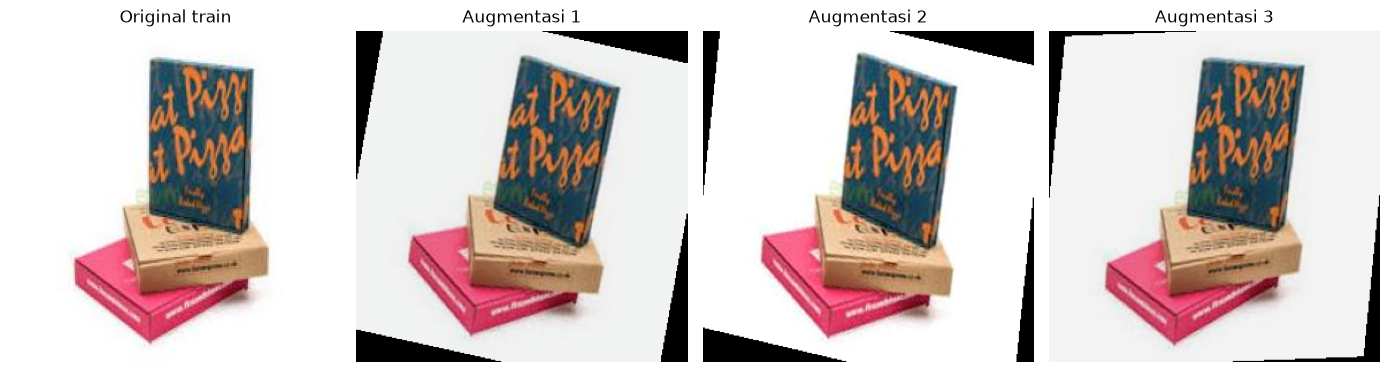

In [6]:
example = coerce_rgb_image(PROJECT_ROOT / train_records[0].processed_relative_path)
figure, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(example); axes[0].set_title("Original train")
for index, axis in enumerate(axes[1:], start=1):
    tensor = TRAIN_TRANSFORM(example)
    restored = tensor * torch.tensor(IMAGENET_STD)[:, None, None] + torch.tensor(IMAGENET_MEAN)[:, None, None]
    axis.imshow(restored.clamp(0, 1).permute(1, 2, 0).numpy()); axis.set_title(f"Augmentasi {index}")
for axis in axes: axis.axis("off")
figure.tight_layout(); display(figure); plt.close(figure)

## 07. DataLoader Construction

Bangun loader hanya untuk train dan validation; `num_workers=0` aman untuk Windows/Jupyter.


In [7]:
train_loader = create_dataloader("train", "efficientnet", batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    seed=SEED, project_root=PROJECT_ROOT, model_config=CONFIG, transform=TRAIN_TRANSFORM, augmentation_enabled=False)
val_loader = create_dataloader("val", "efficientnet", batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    seed=SEED, project_root=PROJECT_ROOT, model_config=CONFIG, transform=VALIDATION_TRANSFORM, augmentation_enabled=False)
print("Train:", len(train_loader.dataset), "Validation:", len(val_loader.dataset), "| Batch:", BATCH_SIZE)

Train: 1340 Validation: 383 | Batch: 8


## 08. Pretrained Model Initialization

Jalankan cell ini secara manual untuk membangun model. Bobot ImageNet akan diunduh oleh torchvision bila belum ada di Torch Hub cache; kegagalan unduh tidak diganti bobot acak.


In [8]:
model = build_efficientnet_b2(8, pretrained=True)
freeze_for_head_training(model)
print("Pretrained terpasang:", WEIGHTS_NAME)
print("Torch Hub cache:", torch.hub.get_dir())

Pretrained terpasang: EfficientNet_B2_Weights.IMAGENET1K_V1
Torch Hub cache: C:\Users\Yafi Rafsanjani H/.cache\torch\hub


## 09. Model Summary

Ringkasan menjalankan satu forward sintetis, bukan training atau inference dataset.


In [9]:
display(model_summary(model, batch_size=2, device=DEVICE))
print("Struktur classifier:", model.classifier)

{'architecture': 'torchvision.models.efficientnet_b2',
 'pretrained_weights': 'EfficientNet_B2_Weights.IMAGENET1K_V1',
 'parameter_counts': {'total': 7712266, 'trainable': 11272},
 'classifier': 'Sequential(\n  (0): Dropout(p=0.3, inplace=True)\n  (1): Linear(in_features=1408, out_features=8, bias=True)\n)',
 'output_shape': (2, 8),
 'device': 'cuda'}

Struktur classifier: Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1408, out_features=8, bias=True)
)


## 10. Phase A Configuration

Backbone dan seluruh BatchNorm backbone dibekukan. Optimizer AdamW head, early stopping validation loss.


In [11]:
HEAD_CONFIG = head_training_config()
HEAD_CONFIG.update({"batch_size": BATCH_SIZE, "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS, "seed": SEED, "amp": DEVICE.type == "cuda"})
print(HEAD_CONFIG)

{'phase': 'head', 'architecture': 'efficientnet_b2', 'model_identifier': 'efficientnet_b2_imagenet1k_v1', 'pretrained_weights': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'preprocessing': {'source': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'color_mode': 'RGB', 'resize': 288, 'center_crop': 288, 'interpolation': 'bicubic', 'pixel_scaling': '[0, 1] before normalization', 'normalization': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'training_augmentation': {'horizontal_flip': True, 'rotation_degrees': 15, 'shear_degrees': 10, 'brightness': 0.1}}, 'batch_norm_policy': 'all backbone BatchNorm layers eval; no running-stat updates', 'optimizer': 'AdamW', 'learning_rate': 0.001, 'weight_decay': 0.0001, 'gradient_clip_norm': 1.0, 'max_epochs': 15, 'early_stopping': {'monitor': 'val_loss', 'mode': 'min', 'patience': 5}, 'batch_size': 8, 'gradient_accumulation_steps': 1, 'seed': 42, 'amp': True}


## 11. Phase A Manual Training

Set `RUN_HEAD_TRAINING=True` pada section 02 dan jalankan cell ini. Untuk melanjutkan run lama, set `RESUME_HEAD=True`; jangan jalankan lagi setelah early stop tanpa keputusan eksplisit.


In [12]:
if RUN_HEAD_TRAINING:
    ensure_experiment_is_safe_to_start(PROJECT_ROOT, HEAD_EXPERIMENT_ID, resume=RESUME_HEAD)
    freeze_for_head_training(model)
    optimizer_a = build_head_optimizer(model)
    manager_a = TrainingManager(model=model, optimizer=optimizer_a, criterion=torch.nn.CrossEntropyLoss(),
        class_mapping=CLASS_MAPPING, model_identifier=MODEL_IDENTIFIER, experiment_id=HEAD_EXPERIMENT_ID,
        project_root=PROJECT_ROOT, device=DEVICE, training_config=HEAD_CONFIG, seed=SEED,
        early_stopping=EarlyStopping(patience=5, min_delta=0.0),
        scaler=torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda"),
        train_mode_callback=lambda active_model: apply_batch_norm_policy(active_model, trainable_batch_norm=False))
    start_a = 0
    if RESUME_HEAD:
        validate_resume_configuration(load_checkpoint(manager_a.checkpoints.last_path)["training_config"], HEAD_CONFIG)
        state = resume_from_checkpoint(manager_a.checkpoints.last_path, model, optimizer_a,
            early_stopping=manager_a.early_stopping, scaler=manager_a.scaler, model_identifier=MODEL_IDENTIFIER,
            class_mapping=CLASS_MAPPING, training_config=None, map_location="cpu")
        start_a, manager_a.history = state.start_epoch, list(state.history)
        manager_a.checkpoints.best_metric, manager_a.checkpoints.best_epoch = state.best_metric, state.best_epoch
        if manager_a.early_stopping.stopped: raise RuntimeError("Run Phase A sudah early-stop; tidak dilanjutkan otomatis.")
    try:
        manager_a.fit(train_loader, val_loader, 15, start_epoch=start_a, amp_enabled=True,
            gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS, gradient_clip_norm=1.0)
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError("CUDA OOM. Hentikan, turunkan BATCH_SIZE menjadi 4 atau 2; gunakan gradient accumulation dan resume eksplisit. Training tidak dimulai ulang otomatis.") from error
    print("Best Phase A:", manager_a.checkpoints.best_path, "val_loss:", manager_a.checkpoints.best_metric)
    model.to("cpu"); del manager_a, optimizer_a
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
else:
    print("Phase A tidak dijalankan.")

Epoch 1/15 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 1/15 | train_loss=0.9989 train_acc=72.09% | val_loss=0.5474 val_acc=87.21% | macro_precision=0.8781 macro_recall=0.8758 macro_f1=0.8735 lr=1.00e-03 lr_changed=False rates=[0.001]->[0.001] | 25.4s | best_epoch=1 best_val_loss=0.5474 | early_stop=0 | BEST SAVED | last_saved=True


Epoch 2/15 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 2/15 | train_loss=0.4391 train_acc=87.91% | val_loss=0.4154 val_acc=88.51% | macro_precision=0.8933 macro_recall=0.8884 macro_f1=0.8871 lr=1.00e-03 lr_changed=False rates=[0.001]->[0.001] | 27.3s | best_epoch=2 best_val_loss=0.4154 | early_stop=0 | BEST SAVED | last_saved=True


Epoch 3/15 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 3/15 | train_loss=0.3442 train_acc=90.75% | val_loss=0.3780 val_acc=90.08% | macro_precision=0.9128 macro_recall=0.9071 macro_f1=0.9041 lr=1.00e-03 lr_changed=False rates=[0.001]->[0.001] | 25.7s | best_epoch=3 best_val_loss=0.3780 | early_stop=0 | BEST SAVED | last_saved=True


... (16 outputs left out)

Epoch 12/15 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 12/15 | train_loss=0.1277 train_acc=96.42% | val_loss=0.3523 val_acc=89.82% | macro_precision=0.9004 macro_recall=0.9031 macro_f1=0.8986 lr=1.00e-03 lr_changed=False rates=[0.001]->[0.001] | 24.8s | best_epoch=8 best_val_loss=0.3125 | early_stop=4 | LAST UPDATED | last_saved=True


Epoch 13/15 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 13/15 | train_loss=0.1265 train_acc=96.27% | val_loss=0.3406 val_acc=89.82% | macro_precision=0.8988 macro_recall=0.9028 macro_f1=0.8982 lr=1.00e-03 lr_changed=False rates=[0.001]->[0.001] | 23.2s | best_epoch=8 best_val_loss=0.3125 | early_stop=5 | LAST UPDATED | last_saved=True
Best Phase A: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\efficientnet_b2_head_v1\best.pt val_loss: 0.3125429521983504


## 12. Phase A History & Learning Curves

Bisa dijalankan setelah restart kernel setelah section 01-02; tidak membuat grafik bila history belum ada.


,experiment_id,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,learning_rates,...,learning_rate_changed,epoch_seconds,best_epoch,best_validation_loss,early_stopping_counter,early_stopping,early_stopping_reason,checkpoint_best_saved,checkpoint_last,checkpoint_status
0,efficientnet_b2_head_v1,0,0.998892,0.720896,0.547419,0.872063,0.878111,0.875784,0.873534,[0.001],...,False,25.429148,0,0.547419,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
1,efficientnet_b2_head_v1,1,0.439101,0.879104,0.415450,0.885117,0.893261,0.888372,0.887140,[0.001],...,False,27.311326,1,0.415450,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
2,efficientnet_b2_head_v1,2,0.344158,0.907463,0.377979,0.900783,0.912777,0.907056,0.904054,[0.001],...,False,25.670950,2,0.377979,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
3,efficientnet_b2_head_v1,3,0.277150,0.917910,0.352852,0.892950,0.895672,0.900237,0.894694,[0.001],...,False,24.274745,3,0.352852,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
4,efficientnet_b2_head_v1,4,0.242101,0.932090,0.346246,0.895561,0.899269,0.898658,0.896353,[0.001],...,False,23.358436,4,0.346246,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
5,efficientnet_b2_head_v1,5,0.202839,0.945522,0.325805,0.903394,0.905890,0.907805,0.904764,[0.001],...,False,23.269997,5,0.325805,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
6,efficientnet_b2_head_v1,6,0.201553,0.944776,0.322891,0.898172,0.901657,0.901978,0.899319,[0.001],...,False,23.355801,6,0.322891,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
7,efficientnet_b2_head_v1,7,0.186318,0.947015,0.312543,0.895561,0.900942,0.897834,0.896398,[0.001],...,False,25.500443,7,0.312543,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,BEST SAVED
8,efficientnet_b2_head_v1,8,0.173479,0.956716,0.329034,0.898172,0.902150,0.901533,0.898972,[0.001],...,False,25.070527,7,0.312543,1,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,LAST UPDATED
9,efficientnet_b2_head_v1,9,0.148670,0.955970,0.335889,0.895561,0.900922,0.900850,0.897285,[0.001],...,False,23.774861,7,0.312543,2,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...,LAST UPDATED


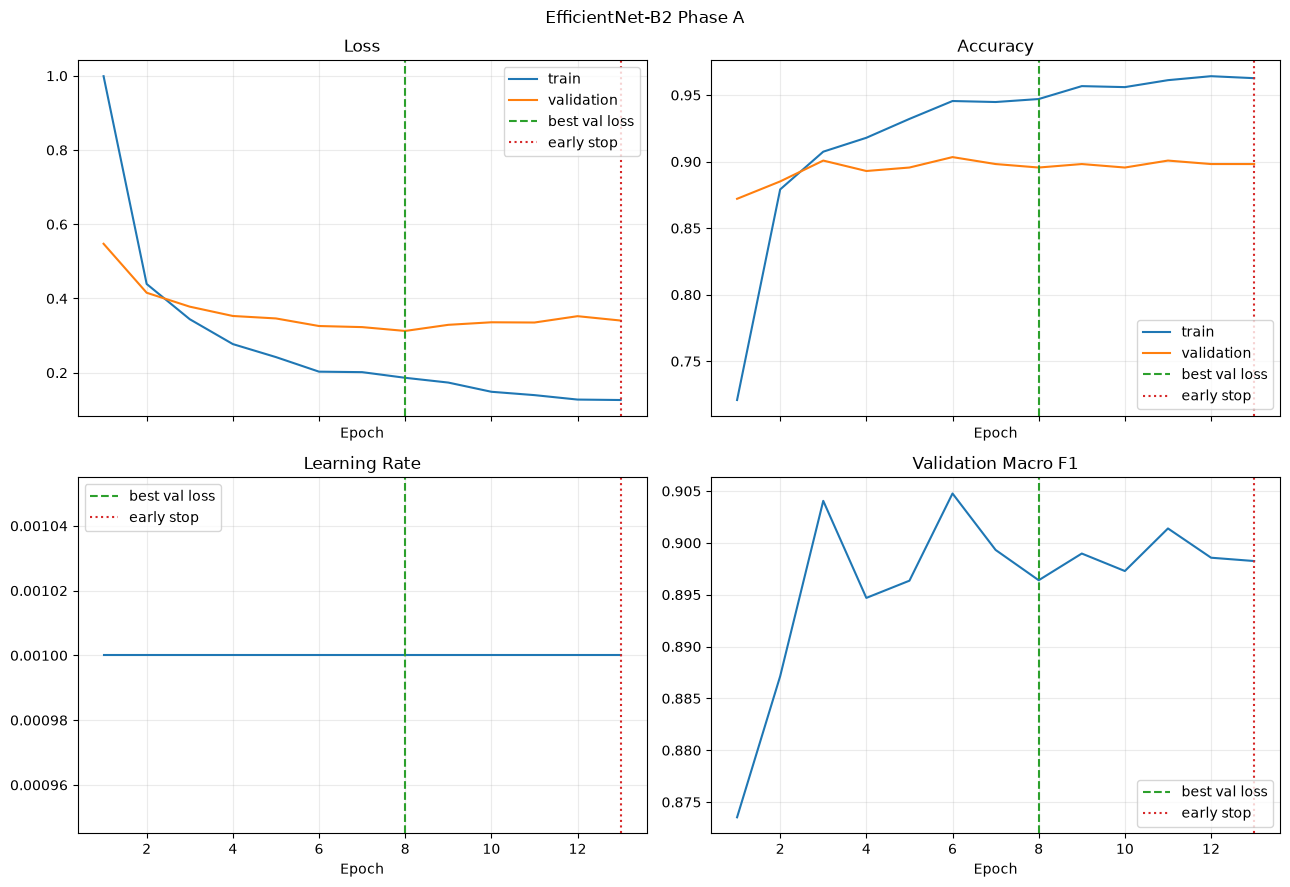

In [13]:
history_a_path = PROJECT_ROOT / "outputs/metrics" / f"{HEAD_EXPERIMENT_ID}.json"
if history_a_path.is_file():
    history_a = load_training_history(history_a_path)
    display(history_review(history_a)["all_epochs"])
    plot_learning_curves(history_a, PROJECT_ROOT / "outputs/figures" / f"{HEAD_EXPERIMENT_ID}_learning_curves.png", title="EfficientNet-B2 Phase A", display_figure=True)
else:
    print("History Phase A belum tersedia.")

## 13. Phase B Configuration

Muat best Phase A; buka hanya dua modul features terakhir. BatchNorm yang tetap frozen tidak mengubah running statistics.


In [15]:
FINETUNE_CONFIG = fine_tuning_config()
FINETUNE_CONFIG.update({"batch_size": BATCH_SIZE, "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS, "seed": SEED, "amp": DEVICE.type == "cuda"})
print(FINETUNE_CONFIG)

{'phase': 'finetune', 'architecture': 'efficientnet_b2', 'model_identifier': 'efficientnet_b2_imagenet1k_v1', 'pretrained_weights': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'preprocessing': {'source': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'color_mode': 'RGB', 'resize': 288, 'center_crop': 288, 'interpolation': 'bicubic', 'pixel_scaling': '[0, 1] before normalization', 'normalization': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'training_augmentation': {'horizontal_flip': True, 'rotation_degrees': 15, 'shear_degrees': 10, 'brightness': 0.1}}, 'unfreeze': 'features[-2:] (final MBConv stage and final convolution)', 'batch_norm_policy': 'frozen BatchNorm eval; trainable final-stage BatchNorm may update', 'optimizer': 'AdamW', 'backbone_learning_rate': 1e-05, 'classifier_learning_rate': 0.0001, 'weight_decay': 0.0001, 'gradient_clip_norm': 1.0, 'max_epochs': 45, 'scheduler': {'name': 'reduce_on_plateau', 'monitor': 'val_loss', 'factor': 0.5, 'patience': 4, 'min_lr': 1

## 14. Phase B Manual Fine-Tuning

Set `RUN_FINE_TUNING=True` setelah Phase A. Optimizer dan scheduler baru; resume Phase B hanya jika `RESUME_FINE_TUNING=True`.


In [16]:
if RUN_FINE_TUNING:
    ensure_experiment_is_safe_to_start(PROJECT_ROOT, FINETUNE_EXPERIMENT_ID, resume=RESUME_FINE_TUNING)
    if "model" in globals():
        model.to("cpu")
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    head_path = PROJECT_ROOT / "models/checkpoints" / HEAD_EXPERIMENT_ID / "best.pt"
    import hashlib
    FINETUNE_CONFIG["parent_head_sha256"] = hashlib.sha256(head_path.read_bytes()).hexdigest()
    loaded_head = load_efficientnet_b2_checkpoint(project_root=PROJECT_ROOT, checkpoint_path=head_path, device=DEVICE)
    model_b = loaded_head.model
    unfrozen = configure_partial_fine_tuning(model_b)
    optimizer_b = build_fine_tuning_optimizer(model_b)
    scheduler_b, scheduler_kind_b = build_scheduler(optimizer_b, {"name": "reduce_on_plateau", "mode": "min", "factor": 0.5, "patience": 4, "min_lr": 1e-7})
    manager_b = TrainingManager(model=model_b, optimizer=optimizer_b, criterion=torch.nn.CrossEntropyLoss(),
        class_mapping=CLASS_MAPPING, model_identifier=MODEL_IDENTIFIER, experiment_id=FINETUNE_EXPERIMENT_ID,
        project_root=PROJECT_ROOT, device=DEVICE, training_config=FINETUNE_CONFIG, seed=SEED,
        scheduler=scheduler_b, scheduler_kind=scheduler_kind_b, early_stopping=EarlyStopping(patience=10, min_delta=0.0),
        scaler=torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda"),
        train_mode_callback=lambda active_model: apply_batch_norm_policy(active_model, trainable_batch_norm=True))
    start_b = 0
    if RESUME_FINE_TUNING:
        validate_resume_configuration(load_checkpoint(manager_b.checkpoints.last_path)["training_config"], FINETUNE_CONFIG)
        state = resume_from_checkpoint(manager_b.checkpoints.last_path, model_b, optimizer_b, scheduler=scheduler_b,
            early_stopping=manager_b.early_stopping, scaler=manager_b.scaler, model_identifier=MODEL_IDENTIFIER,
            class_mapping=CLASS_MAPPING, training_config=None, map_location="cpu")
        start_b, manager_b.history = state.start_epoch, list(state.history)
        manager_b.checkpoints.best_metric, manager_b.checkpoints.best_epoch = state.best_metric, state.best_epoch
        if manager_b.early_stopping.stopped: raise RuntimeError("Run Phase B sudah early-stop; tidak dilanjutkan otomatis.")
    print("Blok trainable:", unfrozen, "| LR:", [group["lr"] for group in optimizer_b.param_groups])
    try:
        manager_b.fit(train_loader, val_loader, 45, start_epoch=start_b, amp_enabled=True,
            gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS, gradient_clip_norm=1.0)
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError("CUDA OOM. Hentikan, turunkan BATCH_SIZE menjadi 4 atau 2; gunakan gradient accumulation dan resume eksplisit. Training tidak dimulai ulang otomatis.") from error
    print("Best Phase B:", manager_b.checkpoints.best_path, "val_loss:", manager_b.checkpoints.best_metric)
    model_b.to("cpu"); del manager_b, optimizer_b, scheduler_b
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
else:
    print("Phase B tidak dijalankan.")

Blok trainable: ['features.7', 'features.8'] | LR: [1e-05, 0.0001]


Epoch 1/45 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 1/45 | train_loss=0.5239 train_acc=81.94% | val_loss=0.4436 val_acc=86.16% | macro_precision=0.8653 macro_recall=0.8654 macro_f1=0.8603 lr=1.00e-05 lr_changed=False rates=[1e-05, 0.0001]->[1e-05, 0.0001] | 19.8s | best_epoch=1 best_val_loss=0.4436 | early_stop=0 | BEST SAVED | last_saved=True


Epoch 2/45 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 2/45 | train_loss=0.4451 train_acc=86.19% | val_loss=0.4290 val_acc=87.73% | macro_precision=0.8802 macro_recall=0.8845 macro_f1=0.8772 lr=1.00e-05 lr_changed=False rates=[1e-05, 0.0001]->[1e-05, 0.0001] | 24.6s | best_epoch=2 best_val_loss=0.4290 | early_stop=0 | BEST SAVED | last_saved=True


Epoch 3/45 train:   0%|          | 0/168 [00:00<?, ?it/s]

... (45 outputs left out)

Epoch 26/45 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 26/45 | train_loss=0.1643 train_acc=94.55% | val_loss=0.3072 val_acc=92.17% | macro_precision=0.9236 macro_recall=0.9229 macro_f1=0.9216 lr=5.00e-06 lr_changed=False rates=[5e-06, 5e-05]->[5e-06, 5e-05] | 24.3s | best_epoch=17 best_val_loss=0.2860 | early_stop=9 | LAST UPDATED | last_saved=True


Epoch 27/45 train:   0%|          | 0/168 [00:00<?, ?it/s]

Epoch 27/45 | train_loss=0.1482 train_acc=95.30% | val_loss=0.2974 val_acc=92.17% | macro_precision=0.9227 macro_recall=0.9235 macro_f1=0.9218 lr=2.50e-06 lr_changed=True rates=[5e-06, 5e-05]->[2.5e-06, 2.5e-05] | 23.5s | best_epoch=17 best_val_loss=0.2860 | early_stop=10 | LAST UPDATED | last_saved=True
Best Phase B: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\efficientnet_b2_finetune_v1\best.pt val_loss: 0.2860141737975044


## 15. Phase A vs Phase B Comparison

Bandingkan best validation loss dari history aktual; Phase B tidak otomatis menang. Grafik dibuat hanya jika history tersedia.


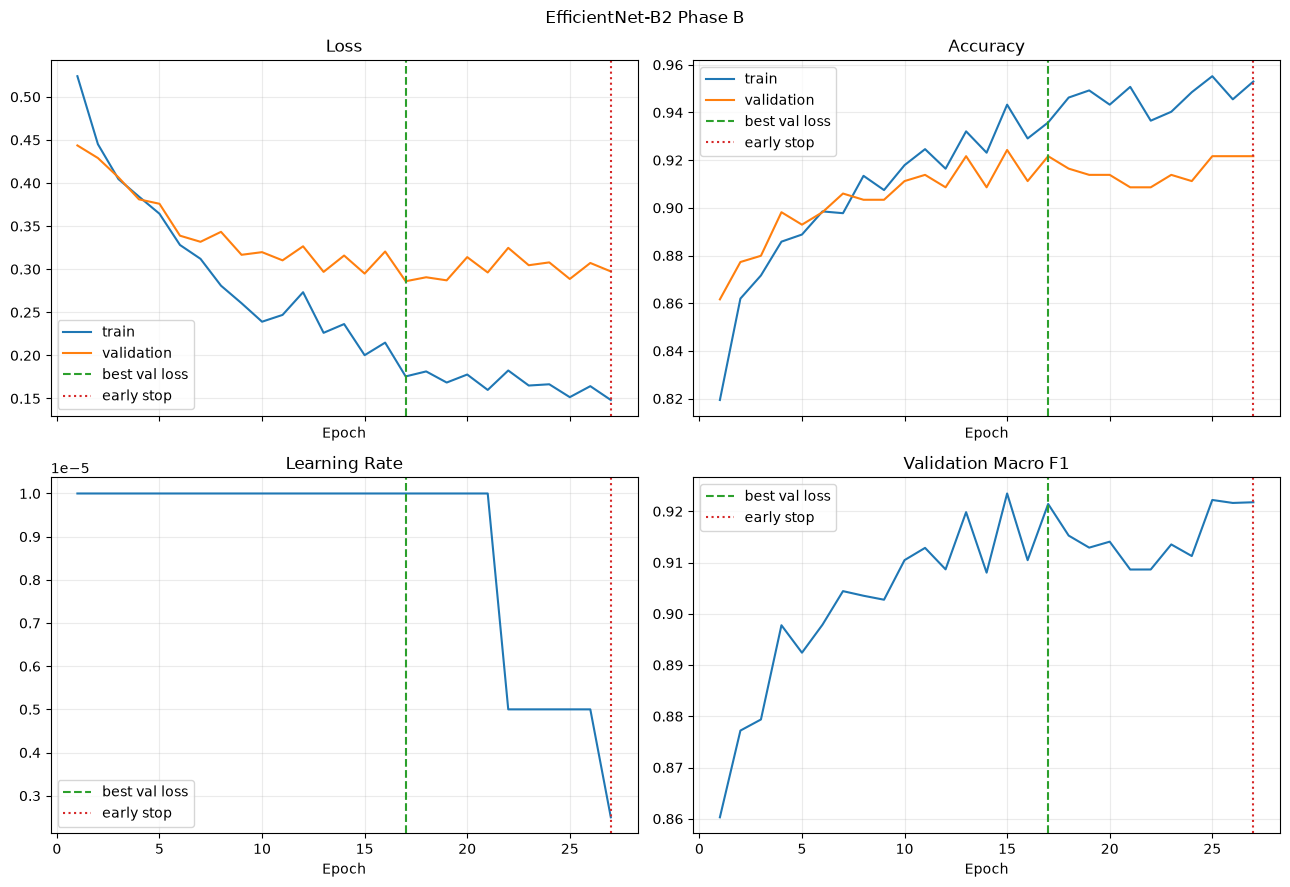

,experiment_id,best_epoch,val_loss,val_accuracy,val_macro_f1
0,efficientnet_b2_head_v1,8,0.312543,0.895561,0.896398
1,efficientnet_b2_finetune_v1,17,0.286014,0.921671,0.921422


In [20]:
phase_rows = []
for experiment_id in (HEAD_EXPERIMENT_ID, FINETUNE_EXPERIMENT_ID):
    history_path = PROJECT_ROOT / "outputs/metrics" / f"{experiment_id}.json"
    if history_path.is_file():
        history = load_training_history(history_path)
        best = min(history, key=lambda row: float(row["val_loss"]))
        phase_rows.append({"experiment_id": experiment_id, "best_epoch": best["epoch"] + 1,
            "val_loss": best["val_loss"], "val_accuracy": best["val_accuracy"], "val_macro_f1": best["val_macro_f1"]})
        if experiment_id == FINETUNE_EXPERIMENT_ID:
            plot_learning_curves(history, PROJECT_ROOT / "outputs/figures" / f"{experiment_id}_learning_curves.png", title="EfficientNet-B2 Phase B", display_figure=True)
display(pd.DataFrame(phase_rows) if phase_rows else "Belum ada history training.")

## 16. Final Best Checkpoint Selection

Memilih minimum validation loss dari `best.pt` Phase A/B; metadata pointer disimpan tanpa menyalin bobot. Phase A saja sudah cukup.


In [21]:
try:
    selected = select_best_phase_checkpoint(PROJECT_ROOT)
    selection_path = save_selected_checkpoint(PROJECT_ROOT, selected)
    print("Terpilih:", selected.phase, selected.checkpoint_path, "val_loss:", selected.val_loss, "| pointer:", selection_path)
except FileNotFoundError as error:
    print(error)

Terpilih: finetune D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\efficientnet_b2_finetune_v1\best.pt val_loss: 0.2860141737975044 | pointer: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\efficientnet_b2_selected_v1.json


## 17. Validation Evaluation

Set `RUN_VALIDATION_EVALUATION=True` untuk evaluasi 383 validation dari checkpoint terpilih. Internal test tidak digunakan.


In [22]:
evaluation = None
if RUN_VALIDATION_EVALUATION:
    selected = select_best_phase_checkpoint(PROJECT_ROOT)
    save_selected_checkpoint(PROJECT_ROOT, selected)
    evaluated_model = load_efficientnet_b2_checkpoint(project_root=PROJECT_ROOT, checkpoint_path=selected.checkpoint_path, device=DEVICE)
    evaluation = validate_one_epoch(evaluated_model.model, val_loader, torch.nn.CrossEntropyLoss(), CLASS_MAPPING, DEVICE)
    assert evaluation["sample_count"] == 383
    evaluation.update({"model_identifier": MODEL_IDENTIFIER, "phase": selected.phase, "checkpoint": str(selected.checkpoint_path.relative_to(PROJECT_ROOT)), "best_checkpoint_val_loss": selected.val_loss})
    metrics_path = PROJECT_ROOT / "outputs/metrics/efficientnet_b2_validation.json"
    metrics_path.parent.mkdir(parents=True, exist_ok=True)
    metrics_path.write_text(json.dumps(evaluation, indent=2), encoding="utf-8")
    display({key: evaluation[key] for key in ("loss", "accuracy", "macro_precision", "macro_recall", "macro_f1", "sample_count", "phase")})
    evaluated_model.model.to("cpu"); del evaluated_model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
else:
    print("Evaluasi validation tidak dijalankan.")

{'loss': 0.2860141737975044,
 'accuracy': 0.9216710182767625,
 'macro_precision': 0.9224916352792729,
 'macro_recall': 0.9231131638597416,
 'macro_f1': 0.9214218875040818,
 'sample_count': 383,
 'phase': 'finetune'}

## 18. Classification Report

Laporan semua kelas dari evaluasi validation yang sebenarnya.


In [23]:
if evaluation is not None:
    display(pd.DataFrame(evaluation["classification_report"]).transpose())
else:
    print("Jalankan evaluasi validation dahulu.")

,precision,recall,f1-score,support
cardboard,0.909091,0.961538,0.934579,52.000000
electronic,0.952381,0.975610,0.963855,41.000000
foodwaste,0.960000,0.979592,0.969697,49.000000
glass,0.918919,0.829268,0.871795,41.000000
metal,0.836364,0.958333,0.893204,48.000000
paper,0.883721,0.844444,0.863636,45.000000
plastic,0.964912,0.859375,0.909091,64.000000
textile,0.954545,0.976744,0.965517,43.000000
accuracy,0.921671,0.921671,0.921671,0.921671
macro avg,0.922492,0.923113,0.921422,383.000000


## 19. Confusion Matrix

Tampilkan confusion matrix mentah dan normalisasi per kelas; simpan grafik berdasarkan evaluasi aktual.


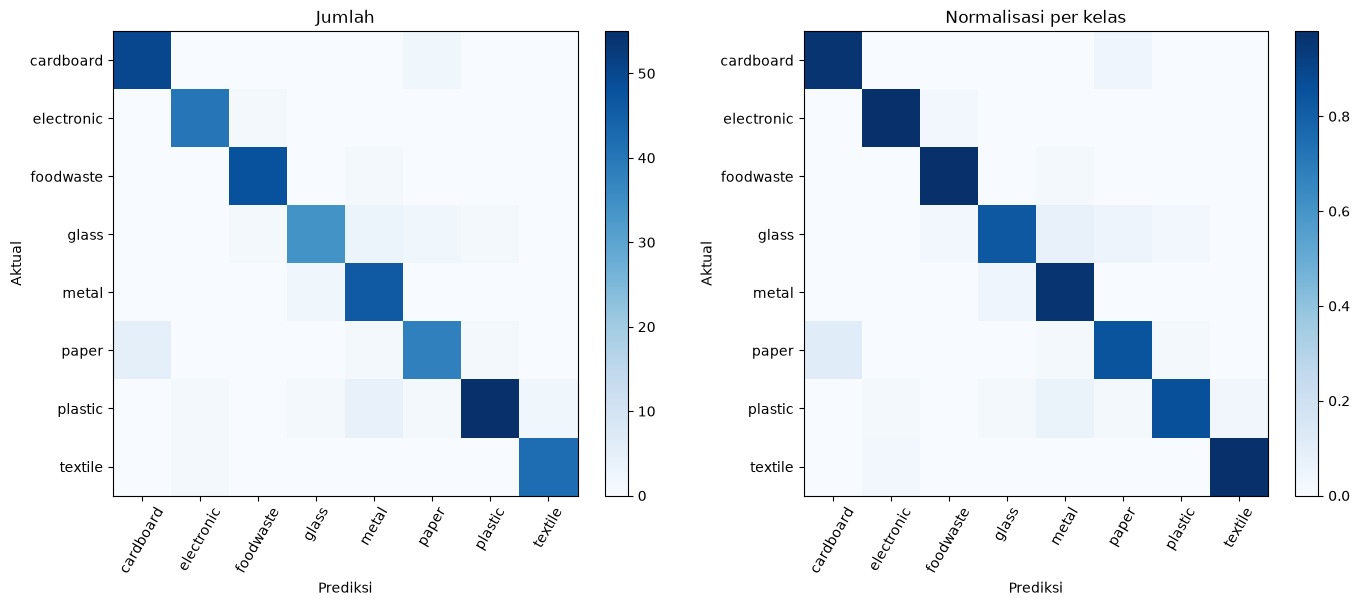

In [24]:
if evaluation is not None:
    matrix = np.asarray(evaluation["confusion_matrix"])
    normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True), out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
    names = [name for name, index in sorted(CLASS_MAPPING.items(), key=lambda item: item[1])]
    figure, axes = plt.subplots(1, 2, figsize=(14, 6))
    for axis, data, title in zip(axes, (matrix, normalized), ("Jumlah", "Normalisasi per kelas")):
        image = axis.imshow(data, cmap="Blues"); figure.colorbar(image, ax=axis, fraction=0.046)
        axis.set(xticks=range(8), yticks=range(8), xticklabels=names, yticklabels=names, title=title, xlabel="Prediksi", ylabel="Aktual")
        axis.tick_params(axis="x", labelrotation=60)
    figure.tight_layout(); output = PROJECT_ROOT / "outputs/figures/efficientnet_b2_confusion_matrix.png"
    output.parent.mkdir(parents=True, exist_ok=True); figure.savefig(output, dpi=160); display(figure); plt.close(figure)
else:
    print("Jalankan evaluasi validation dahulu.")

## 20. Training Diagnostics

Heuristik saja: bandingkan gap train-validation dan loss terakhir dengan loss minimum; bukan bukti final generalisasi.


In [25]:
if phase_rows:
    for row in phase_rows:
        history = load_training_history(PROJECT_ROOT / "outputs/metrics" / f"{row['experiment_id']}.json")
        last = history[-1]; best = min(history, key=lambda item: float(item["val_loss"]))
        gap = float(last["train_accuracy"]) - float(last["val_accuracy"])
        print(row["experiment_id"], "train-val accuracy gap:", round(gap, 4), "last/best val loss:", round(float(last["val_loss"]), 4), "/", round(float(best["val_loss"]), 4))
        print("Indikasi:", "potensi overfitting" if gap > 0.1 and float(last["val_loss"]) > float(best["val_loss"]) else "periksa kurva untuk underfitting atau plateau; tidak ada kesimpulan otomatis")
else:
    print("Tidak ada history untuk diagnosis.")

efficientnet_b2_head_v1 train-val accuracy gap: 0.0645 last/best val loss: 0.3406 / 0.3125
Indikasi: periksa kurva untuk underfitting atau plateau; tidak ada kesimpulan otomatis
efficientnet_b2_finetune_v1 train-val accuracy gap: 0.0313 last/best val loss: 0.2974 / 0.286
Indikasi: periksa kurva untuk underfitting atau plateau; tidak ada kesimpulan otomatis


## 21. Competition Test Audit

Audit hanya `data/competition/test/` dan ID pada sample. Kolom kategori sample bukan ground truth dan tidak digunakan.


In [26]:
competition_audit = audit_competition_test(project_root=PROJECT_ROOT, expected_count=480)
display(competition_audit.to_dict())

{'test_directory': 'D:\\FILE KULIAH\\Lomba Gelar 2026\\DSC_2026_Waste_Classification\\data\\competition\\test',
 'image_count': 480,
 'readable_image_count': 480,
 'extensions': {'.jpeg': 2, '.jpg': 477, '.png': 1},
 'formats': {'JPEG': 479, 'PNG': 1},
 'color_modes': {'RGB': 480},
 'unique_dimensions': 51,
 'sample_submission_path': 'D:\\FILE KULIAH\\Lomba Gelar 2026\\DSC_2026_Waste_Classification\\data\\competition\\SampleSubmission_DSC.csv',
 'sample_columns': ('image_id', 'waste_category'),
 'sample_row_count': 480,
 'expected_count': 480}

## 22. Standalone Inference Setup

Setelah kernel baru, jalankan **cell ini saja**. Ia menemukan root, memeriksa dependensi, config, checkpoint, transform dan 480 file; tidak melakukan prediksi.


In [27]:
from pathlib import Path
import sys
import importlib
import warnings
import json
import csv
from collections import Counter

def inference_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "data/metadata/split_manifest.csv").is_file() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Root proyek tidak ditemukan. Jalankan dari root atau notebooks.")

INFERENCE_ROOT = inference_project_root()
if str(INFERENCE_ROOT) not in sys.path: sys.path.insert(0, str(INFERENCE_ROOT))
for dependency in ("torch", "torchvision", "numpy", "PIL", "yaml", "pandas", "sklearn", "tqdm", "albumentations", "cv2"):
    try: importlib.import_module(dependency)
    except Exception as error: raise ImportError(f"Dependensi inference {dependency!r} tidak tersedia/bermasalah: {error}") from error
import torch
import pandas as pd
from IPython.display import display
from src.data.preprocessing import coerce_rgb_image, load_active_class_mapping
from src.models.efficientnet_b2 import (load_experiment_config, load_selected_checkpoint,
    load_efficientnet_b2_checkpoint, build_efficientnet_b2_transforms, validate_preprocessing,
    EfficientNetB2Error)
from src.inference.competition import (competition_paths, audit_competition_test, load_submission_template,
    CompetitionTestDataset, create_competition_dataloader)
from src.inference.predict import predict_torch_classifier
from src.inference.submission import write_submission_csv, validate_submission_csv

INFERENCE_CONFIG = load_experiment_config(INFERENCE_ROOT)
INFERENCE_MAPPING = load_active_class_mapping(INFERENCE_ROOT)
if len(INFERENCE_MAPPING) != 8: raise ValueError("Mapping kelas aktif harus memiliki delapan kelas.")
INFERENCE_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if INFERENCE_DEVICE.type == "cpu": warnings.warn("CUDA tidak tersedia, inference memakai CPU.")
_, INFERENCE_TRANSFORM, INFERENCE_PREPROCESSING = build_efficientnet_b2_transforms()
print("Transform:", validate_preprocessing(INFERENCE_TRANSFORM))
INFERENCE_TEST_DIR, INFERENCE_SAMPLE_PATH = competition_paths(INFERENCE_ROOT)
INFERENCE_TEMPLATE = load_submission_template(INFERENCE_SAMPLE_PATH)
INFERENCE_AUDIT = audit_competition_test(project_root=INFERENCE_ROOT, expected_count=480)
INFERENCE_OUTPUT = INFERENCE_ROOT / "Final Dataset for Submission to Kaggle/submission_efficientnet_b2.csv"
INFERENCE_SELECTED = load_selected_checkpoint(INFERENCE_ROOT)
if INFERENCE_SELECTED.preprocessing != INFERENCE_PREPROCESSING or INFERENCE_SELECTED.class_mapping != INFERENCE_MAPPING:
    raise EfficientNetB2Error("Metadata preprocessing atau class mapping checkpoint tidak cocok.")
INFERENCE_LOADED = load_efficientnet_b2_checkpoint(project_root=INFERENCE_ROOT,
    checkpoint_path=INFERENCE_SELECTED.checkpoint_path, device=INFERENCE_DEVICE, expected_class_mapping=INFERENCE_MAPPING)
if INFERENCE_LOADED.model.classifier[-1].out_features != 8: raise ValueError("Classifier bukan delapan kelas.")
print("Root:", INFERENCE_ROOT, "Device:", INFERENCE_DEVICE, "Checkpoint:", INFERENCE_SELECTED)
print("Audit test:", INFERENCE_AUDIT.to_dict())

Transform: {'shape': (3, 288, 288), 'dtype': 'torch.float32', 'finite': True}
Root: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification Device: cuda Checkpoint: SelectedCheckpoint(phase='finetune', experiment_id='efficientnet_b2_finetune_v1', checkpoint_path=WindowsPath('D:/FILE KULIAH/Lomba Gelar 2026/DSC_2026_Waste_Classification/models/checkpoints/efficientnet_b2_finetune_v1/best.pt'), val_loss=0.2860141737975044, epoch=16, class_mapping={'cardboard': 0, 'electronic': 1, 'foodwaste': 2, 'glass': 3, 'metal': 4, 'paper': 5, 'plastic': 6, 'textile': 7}, preprocessing={'source': 'EfficientNet_B2_Weights.IMAGENET1K_V1', 'color_mode': 'RGB', 'resize': 288, 'center_crop': 288, 'interpolation': 'bicubic', 'pixel_scaling': '[0, 1] before normalization', 'normalization': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'training_augmentation': {'horizontal_flip': True, 'rotation_degrees': 15, 'shear_degrees': 10, 'brightness': 0.1}})
Audit test: {'test_directory': 'D:\

## 23. Manual Test Inference

Set flag di cell ini ke `True` hanya ketika siap; cell ini berdiri sendiri setelah section 22, memuat ulang checkpoint dan tidak menimpa CSV yang ada.


In [28]:
RUN_TEST_INFERENCE = True
if RUN_TEST_INFERENCE:
    INFERENCE_LOADED = load_efficientnet_b2_checkpoint(project_root=INFERENCE_ROOT,
        checkpoint_path=INFERENCE_SELECTED.checkpoint_path, device=INFERENCE_DEVICE, expected_class_mapping=INFERENCE_MAPPING)
    INFERENCE_DATASET = CompetitionTestDataset(model_type="efficientnet", project_root=INFERENCE_ROOT,
        expected_count=480, transform=lambda path: INFERENCE_TRANSFORM(coerce_rgb_image(path)))
    INFERENCE_LOADER = create_competition_dataloader(INFERENCE_DATASET, batch_size=8, num_workers=0)
    try:
        predictions = predict_torch_classifier(INFERENCE_LOADED.model, INFERENCE_LOADER,
            index_to_class=INFERENCE_LOADED.index_to_class, device=INFERENCE_DEVICE)
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError("CUDA OOM saat inference. Kurangi batch_size menjadi 4 atau 2 dan jalankan ulang secara manual.") from error
    write_submission_csv(INFERENCE_TEMPLATE, predictions, INFERENCE_OUTPUT, allowed_classes=INFERENCE_MAPPING, overwrite=False)
    validate_submission_csv(INFERENCE_OUTPUT, INFERENCE_TEMPLATE, allowed_classes=INFERENCE_MAPPING)
    print("Submission dibuat:", INFERENCE_OUTPUT)
else:
    print("Inference test tidak dijalankan.")

Submission dibuat: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\Final Dataset for Submission to Kaggle\submission_efficientnet_b2.csv


## 24. Submission CSV Verification

Validasi CSV yang sudah dibuat tanpa menjalankan inference ulang. Tetap memerlukan standalone setup section 22.


In [29]:
if INFERENCE_OUTPUT.is_file():
    validate_submission_csv(INFERENCE_OUTPUT, INFERENCE_TEMPLATE, allowed_classes=INFERENCE_MAPPING)
    submission = pd.read_csv(INFERENCE_OUTPUT, dtype={"image_id": str})
    assert list(submission.columns) == ["image_id", "waste_category"] and len(submission) == 480
    display(submission.head())
    display(submission["waste_category"].value_counts().reindex(list(INFERENCE_MAPPING), fill_value=0).rename("count"))
    print("CSV valid; urutan ID dan leading zero dipertahankan.")
else:
    print("CSV belum ada; inference belum dijalankan.")

,image_id,waste_category
0,001,textile
1,002,foodwaste
2,003,foodwaste
3,004,metal
4,005,paper


waste_category
cardboard     61
electronic    57
foodwaste     63
glass         58
metal         70
paper         57
plastic       56
textile       58
Name: count, dtype: int64

CSV valid; urutan ID dan leading zero dipertahankan.


## 25. Experiment Summary

Ringkasan artefak dan status; tidak mengklaim model telah dilatih atau CSV telah dibuat.


In [30]:
print("Dataset lama V1: eksperimen teknis, bukan kepatuhan aturan lima label manual per kelas.")
print("Checkpoints:", PROJECT_ROOT / "models/checkpoints" / HEAD_EXPERIMENT_ID, "dan", PROJECT_ROOT / "models/checkpoints" / FINETUNE_EXPERIMENT_ID)
print("History:", PROJECT_ROOT / "outputs/metrics", "| Log:", PROJECT_ROOT / "outputs/logs", "| Grafik:", PROJECT_ROOT / "outputs/figures")
print("Submission target:", PROJECT_ROOT / "Final Dataset for Submission to Kaggle/submission_efficientnet_b2.csv")

Dataset lama V1: eksperimen teknis, bukan kepatuhan aturan lima label manual per kelas.
Checkpoints: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\efficientnet_b2_head_v1 dan D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\efficientnet_b2_finetune_v1
History: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\outputs\metrics | Log: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\outputs\logs | Grafik: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\outputs\figures
Submission target: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\Final Dataset for Submission to Kaggle\submission_efficientnet_b2.csv
